# CatBoost Regressor — SAR Prediction
## ML Workflow: Data Loading → Preprocessing → Training → Evaluation → Interpretability

**Target:** `f_SAR_W_g` (Specific Absorption Rate, W/g)  
**Model:** CatBoost with Optuna hyperparameter optimisation  
**Workflow order:** Load → EDA → Split → Feature Engineering → Impute → Scale → Train → Evaluate → SHAP → PDP

## 1. Installation

In [ ]:
# Run once to install dependencies
%pip install catboost optuna seaborn shap xgboost missforest --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 7.4 MB/s eta 0:00:00


## 2. Imports & Constants

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap as s
import optuna as op

from catboost import CatBoostRegressor, Pool
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer,MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import cross_val_predict
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from missforest import MissForest
from scipy.optimize import minimize, differential_evolution, NonlinearConstraint
from scipy.spatial.distance import cdist
import random
from itertools import combinations

TARGET       = 'f_SAR_W_g'
DROP_COLS    = ['-', 'DOI', 'c_core_composition', 'c_dopant_element', 'f_dopant_ratio']
CAT_COLS     = ['c_shape_type', 'c_magnetic_phase', 'c_coating']
RANDOM_STATE = 62

sns.set_theme(style="whitegrid")

## 3. Helper Functions

In [ ]:
def clean_df_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [c.replace('\ufeff', '').replace('\u200b', '').strip() for c in df.columns]
    return df


def add_flag_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['f_is_coated'] = df['c_coating'].apply(lambda v: 0 if pd.isna(v) else 1)
    df['f_is_shaped']  = df['c_shape_type'].apply(lambda v: 0 if pd.isna(v) else 1)
    df['f_is_phased']  = df['c_magnetic_phase'].apply(lambda v: 0 if pd.isna(v) else 1)
    return df

## 4. Data Loading

In [ ]:
df = pd.read_excel("Final.xlsx")
df = clean_df_columns(df)
df.drop(columns=[c for c in DROP_COLS if c in df.columns], inplace=True)

print(f"Dataset shape: {df.shape}")
print(f"\nColumn dtypes:\n{df.dtypes}")
print(f"\nMissing values (%):\n{(df.isnull().mean() * 100).round(2)}")
df.head()

Dataset shape: (1548, 32)

Column dtypes:
f_avg_core_width_nm            float64
f_Ms_emu_g_MNP                 float64
f_Hc_Oe                        float64
is_doped                         int64
f_is_coated                      int64
f_is_organic                     int64
f_is_inorganic                   int64
f_is_composite_coating           int64
c_coating                       object
f_H_Oe                         float64
f_FCY_kHz                      float64
f_conc_MNP_mg_mL               float64
c_shape_type                    object
c_magnetic_phase                object
f_SAR_W_g                      float64
f_avg_core_sd_nm _BOTH         float64
f_area_core_estimated_nm2      float64
f_volume_core_estimated_nm3    float64
f_area_volume_ratio            float64
Ca_comp                        float64
Co_comp                        float64
Cu_comp                        float64
Fe_comp                        float64
Ga_comp                        float64
Gd_comp               

,f_avg_core_width_nm,f_Ms_emu_g_MNP,f_Hc_Oe,is_doped,f_is_coated,f_is_organic,f_is_inorganic,f_is_composite_coating,c_coating,f_H_Oe,...,Fe_comp,Ga_comp,Gd_comp,Mg_comp,Mn_comp,Nd_comp,Ni_comp,Sn_comp,Tb_comp,Zn_comp
0,15.0,60.00,0.0,0,0,0,0,0,NaN,600.00,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
1,17.0,36.78,6.0,1,1,1,0,0,Chitosan,187.42,...,2.93,0.0,0.07,0.0,0.0,0.0,0.0,0,0.0,0.0
2,75.0,60.00,100.0,0,0,0,0,0,NaN,300.00,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
3,19.9,53.10,4.0,0,1,1,0,0,TREG-coated,238.83,...,2.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
4,14.6,54.40,3.0,0,0,0,0,0,NaN,300.00,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0


## 5. Exploratory Data Analysis

A quick look at the target distribution and dopant–SAR relationships.  
These plots use the *full* dataset intentionally — they are observational only and do not influence the model.

In [ ]:
# 5a. Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df[TARGET], bins=40, edgecolor='white', color='steelblue')
axes[0].set_title(f'Raw {TARGET} distribution')
axes[0].set_xlabel('SAR (W/g)')

axes[1].hist(np.log1p(df[TARGET]), bins=40, edgecolor='white', color='darkorange')
axes[1].set_title(f'log1p({TARGET}) distribution')
axes[1].set_xlabel('log1p(SAR)')

plt.suptitle('Target Variable Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150)
plt.show()

In [ ]:
# 5b. SAR vs individual dopant concentrations (full dataset, log–log scale)
dopant_cols_eda = [c for c in df.columns if c.endswith('_comp')]
plot_df = df[dopant_cols_eda + [TARGET]].copy()

n_cols_plot = 2
n_rows_plot = int(np.ceil(len(dopant_cols_eda) / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot,
                          figsize=(14, n_rows_plot * 3.5))
axes = np.array(axes).flatten()

for i, col in enumerate(dopant_cols_eda):
    ax = axes[i]
    sub = plot_df[plot_df[col] > 0]
    if sub.empty:
        ax.set_visible(False)
        continue
    sns.scatterplot(data=sub, x=col, y=TARGET, alpha=0.7, ax=ax)
    sns.regplot(data=sub, x=col, y=TARGET, scatter=False,
                color='red', lowess=True,
                line_kws={'alpha': 0.8, 'linestyle': '--'}, ax=ax)
    ax.set_title(col.replace('_comp', ''), fontsize=10)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.grid(True, which='both', ls='--', c='0.7')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('SAR vs Dopant Concentration', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('dopant_sar_scatter.png', dpi=150)
plt.show()

## 6. Train / Validation / Test Split

The split is performed **before** any feature engineering or preprocessing to prevent data leakage.  
Preprocessing objects (imputer, scaler) are fitted **only** on the training set.

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# 80 / 10 / 10 split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE)

print(f"Train : {X_train.shape[0]:>4d} samples  ({100*len(X_train)/len(X):.1f}%)")
print(f"Val   : {X_val.shape[0]:>4d} samples  ({100*len(X_val)/len(X):.1f}%)")
print(f"Test  : {X_test.shape[0]:>4d} samples  ({100*len(X_test)/len(X):.1f}%)")

Train : 1238 samples  (80.0%)
Val   :  155 samples  (10.0%)
Test  :  155 samples  (10.0%)


## 7. Feature Engineering

Applied identically to all splits.  No statistics from val/test are used here.

In [ ]:
X_train = add_flag_features(X_train)
X_val   = add_flag_features(X_val)
X_test  = add_flag_features(X_test)

# Refresh column lists after feature engineering
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols     = X_train.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numeric features : {len(numeric_cols)}")
print(f"Categorical features: {len(cat_cols)}")

Numeric features : 30
Categorical features: 3


## 8. Missing Value Imputation

- **Numeric columns**: MissForest (iterative RF imputer) — fitted on train only, then applied to val/test.  
- **Categorical columns**: fill with `'Unknown'`.

In [ ]:

imputer = MissForest(rgr=RandomForestRegressor(n_estimators=100,random_state=62),max_iter=10)

for col in cat_cols:
    X_train[col] = X_train[col].fillna('Unknown').astype(str)
    X_val[col]   = X_val[col].fillna('Unknown').astype(str)
    X_test[col]  = X_test[col].fillna('Unknown').astype(str)

if X_train[numeric_cols].isnull().any().any():
    imputer = MissForest(
        rgr=RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
        max_iter=10
    )
    X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])
    X_val[numeric_cols]   = imputer.transform(X_val[numeric_cols])
    X_test[numeric_cols]  = imputer.transform(X_test[numeric_cols])
    print("Numeric columns imputed with MissForest.")
else:
    print("No missing values in numeric columns — skipping imputation.")

/usr/local/lib/python3.12/dist-packages/missforest/missforest.py:333: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
 30%|███       | 3/10 [01:10<02:36, 22.43s/it]/usr/local/lib/python3.12/dist-packages/missforest/missforest.py:303: UserWarning: NRMSE increased.
  warnings.warn("NRMSE increased.")
/usr/local/lib/python3.12/dist-packages/missforest/missforest.py:453: UserWarning: Stopping criterion triggered during fitting. Before last imputation matrix will be returned.
  warnings.warn(
 30%|███       | 3/10 [01:31<03:34, 30.64s/it]
/usr/local/lib/python3.12/dist-packages/missforest/missforest.py:490: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
/usr/local/lib/python3.12/dist

Numeric columns imputed with MissForest.


## 9. Feature Scaling

`QuantileTransformer` maps numeric features to a normal distribution.  
Fitted on train only; transform applied to all splits.

In [ ]:
X_train_raw = X_train.copy()
X_val_raw   = X_val.copy()
X_test_raw  = X_test.copy()

qt_scaler = QuantileTransformer(output_distribution='normal', random_state=RANDOM_STATE)
X_train[numeric_cols] = qt_scaler.fit_transform(X_train[numeric_cols])
X_val[numeric_cols]   = qt_scaler.transform(X_val[numeric_cols])
X_test[numeric_cols]  = qt_scaler.transform(X_test[numeric_cols])

print("Scaling complete.")
print("X_train shape:", X_train.shape)

NameError: name 'X_train' is not defined

In [ ]:
y_train_log = np.log1p(y_train.astype(float))   # log1p on raw SAR
y_val_log   = np.log1p(y_val.astype(float))
y_test_log  = np.log1p(y_test.astype(float))

y_scaler = MinMaxScaler()
y_train = y_scaler.fit_transform(y_train_log.to_frame()).flatten()
y_val   = y_scaler.transform(y_val_log.to_frame()).flatten()
y_test  = y_scaler.transform(y_test_log.to_frame()).flatten()

print("=== Scaler sanity check ===")
print(f"  data_min_ : {y_scaler.data_min_[0]:.4f}  "
      f"(= log1p({np.expm1(y_scaler.data_min_[0]):.2f} W/g)")
print(f"  data_max_ : {y_scaler.data_max_[0]:.4f}  "
      f"(= log1p({np.expm1(y_scaler.data_max_[0]):.2f} W/g)")

def inverse_sar(y_scaled: np.ndarray, fitted_scaler: MinMaxScaler) -> np.ndarray:
  y_scaled_clipped = np.clip(y_scaled, 0.0, 1.0)
  pred_log_units      = fitted_scaler.inverse_transform(y_scaled_clipped.reshape(-1, 1)).flatten()
  true_predicted_sar  = np.expm1(pred_log_units)
  return true_predicted_sar


=== Scaler sanity check ===
  data_min_ : 0.1570  (= log1p(0.17 W/g)
  data_max_ : 8.6145  (= log1p(5510.00 W/g)


## 10. Build CatBoost Pools

In [ ]:
train_pool = Pool(X_train, y_train, cat_features=cat_cols)
val_pool   = Pool(X_val,   y_val,   cat_features=cat_cols)

print("Pools ready.")

Pools ready.


## 11. Hyperparameter Optimisation (Optuna)

Minimise validation RMSE over 200 trials using TPE sampler.  
Results are persisted to `catboost_optuna.db` so trials survive kernel restarts.

In [ ]:
def objective(trial):
    params = dict(
        iterations    = trial.suggest_int('iterations',100,1000),
        learning_rate = trial.suggest_float('learning_rate',0.01,0.1,log=True),
        depth         = trial.suggest_int('depth',3,8),
        l2_leaf_reg   = trial.suggest_float('l2_leaf_reg',5,20),
        border_count  = trial.suggest_int('border_count',50,150),
        subsample     = trial.suggest_float('subsample',0.6,0.8),
        random_seed   = RANDOM_STATE,
        loss_function = 'RMSE',
        cat_features  = cat_cols,
        verbose       = False,
    )
    cb = CatBoostRegressor(**params)
    cb.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)
    return cb.best_score_['validation']['RMSE']


study = op.create_study(
    direction='minimize',
    sampler=op.samplers.TPESampler(),
    storage='sqlite:///catboost_optuna.db',
    load_if_exists=True,
)
study.optimize(objective, n_trials=200)

print("Best params :", study.best_params)
print("Best val RMSE:", round(study.best_value, 4))

[I 2026-07-30 06:11:26,206] A new study created in RDB with name: no-name-f6ee60c8-2c69-4abb-95d8-dec3465d34f9
[I 2026-07-30 06:11:27,255] Trial 0 finished with value: 0.10130737147295413 and parameters: {'iterations': 459, 'learning_rate': 0.03497016897375463, 'depth': 4, 'l2_leaf_reg': 15.18594350548102, 'border_count': 86, 'subsample': 0.7813161882493648}. Best is trial 0 with value: 0.10130737147295413.
[I 2026-07-30 06:11:31,593] Trial 1 finished with value: 0.09932855254074677 and parameters: {'iterations': 872, 'learning_rate': 0.010272644311122221, 'depth': 6, 'l2_leaf_reg': 5.9698592884123745, 'border_count': 82, 'subsample': 0.694198285701179}. Best is trial 1 with value: 0.09932855254074677.
[I 2026-07-30 06:11:33,164] Trial 2 finished with value: 0.10479199315811472 and parameters: {'iterations': 515, 'learning_rate': 0.021593287248548726, 'depth': 5, 'l2_leaf_reg': 19.406797012303713, 'border_count': 130, 'subsample': 0.6311827963845525}. Best is trial 1 with value: 0.0993

Best params : {'iterations': 936, 'learning_rate': 0.0999537304363189, 'depth': 7, 'l2_leaf_reg': 5.748830731364533, 'border_count': 95, 'subsample': 0.6022081251972473}
Best val RMSE: 0.0807


## 12. Final Model Training

Retrain with best hyperparameters using `use_best_model=True`.

In [ ]:
# Best params : {'iterations': 936, 'learning_rate': 0.0999537304363189, 'depth': 7, 'l2_leaf_reg': 5.748830731364533, 'border_count': 95, 'subsample': 0.6022081251972473}Best val RMSE: 0.0807
catboost_model = CatBoostRegressor(**study.best_params,random_seed=RANDOM_STATE,verbose=False,)
catboost_model.fit(train_pool,eval_set=val_pool,use_best_model=True,early_stopping_rounds=50,)
print("Training complete.")

Training complete.


## 13. Model Evaluation

Metrics reported on the **log-transformed** scale (matching training objective).  
`±q90` is the 90th-percentile absolute error.

In [ ]:
y_val_pred  = catboost_model.predict(X_val)
y_test_pred = catboost_model.predict(X_test)

val_r2    = r2_score(y_val,  y_val_pred)
test_r2   = r2_score(y_test, y_test_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_q90  = np.quantile(np.abs(y_test - y_test_pred), 0.90)

def inverse_sar(y_scaled: np.ndarray, fitted_scaler: MinMaxScaler) -> np.ndarray:
  y_scaled_clipped = np.clip(y_scaled, 0.0, 1.0)
  pred_log_units      = fitted_scaler.inverse_transform(y_scaled_clipped.reshape(-1, 1)).flatten()
  true_predicted_sar  = np.expm1(pred_log_units)
  return true_predicted_sar

y_test=inverse_sar(y_test,y_scaler)
y_test_pred=inverse_sar(y_test_pred,y_scaler)
err_90 = np.quantile(np.abs(y_test - y_test_pred), 0.90)

print(f"Validation  — R²: {val_r2:.4f}   RMSE: {val_rmse:.4f}")
print(f"Test        — R²: {test_r2:.4f}   RMSE: {test_rmse:.4f}")
print(f"90th-pct prediction error (test): ±{err_90:.4f}")

Validation  — R²: 0.7681   RMSE: 0.0807
Test        — R²: 0.7932   RMSE: 0.0726
90th-pct prediction error (test): ±106.0384


In [ ]:
# residuals = y_test_log - y_test_pred
# plt.figure(figsize=(8, 5))
# sns.histplot(residuals, kde=True)
# plt.title("Distribution of Residuals", fontsize=12, fontweight="bold")
# plt.xlabel("Residual (Actual − Predicted)")
# plt.ylabel("Frequency")
# plt.tight_layout()
# plt.savefig("residual_distribution.png", dpi=150)
# plt.show()

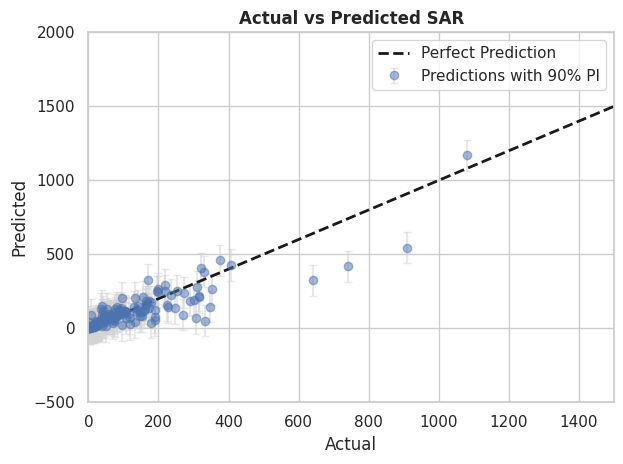

In [ ]:
plt.errorbar(y_test,y_test_pred, yerr=err_90, fmt='o', alpha=0.5, ecolor='lightgray', capsize=3, label='Predictions with 90% PI')
plt.plot([0, 1500], [0, 1500], 'k--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
plt.xlim([0, 1500])
plt.ylim([-500, 2000])
plt.title("Actual vs Predicted SAR", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("actual_vs_predicted_PI.png", dpi=150)
plt.show()

## 14. Feature Importance (SHAP)

SHAP values are computed on the training set.  
`X_train` here contains features only (no target column).

In [ ]:
explainer    = s.TreeExplainer(catboost_model)
shap_values  = explainer.shap_values(X_train)
importance   = np.abs(shap_values).mean(axis=0)

feature_importance = pd.DataFrame({
    'feature':    X_train.columns,
    'importance': importance,
}).sort_values('importance', ascending=False)

print(feature_importance.to_string(index=False))

s.summary_plot(shap_values, X_train, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150)
plt.show()

In [ ]:
# Dopant-specific importance ranking
dopant_importance = (feature_importance[feature_importance['feature'].str.contains('_comp')]
                     .copy())
dopant_importance['dopant'] = dopant_importance['feature'].str.replace('_comp', '', regex=False)
dopant_importance.sort_values('importance', ascending=False, inplace=True)

print("\n--- Dopant Ranking (SHAP) ---")
print(" > ".join(dopant_importance['dopant']))

plt.figure(figsize=(12, 6))
sns.barplot(data=dopant_importance, x='dopant', y='importance', palette='viridis')
plt.title('Dopant Impact on SAR (Mean |SHAP|)')
plt.xlabel('Dopant Element')
plt.ylabel('Mean |SHAP| Value')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('dopant_importance.png', dpi=150)
plt.show()

## 15. Dopant & Linear Response Theory (LRT) Analysis

A separate `RandomForestRegressor` is trained exclusively on the **training split** for
interpretability experiments.  The `catboost_model` from §13 is unaffected.

In [ ]:
features  = ['f_H_Oe', 'f_FCY_kHz', 'f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'is_doped']
dopant_cols  = [c for c in df.columns if c.endswith('_comp') and c != 'Fe_comp']
all_feats = features + dopant_cols

# Build an analysis dataframe from the training split only
train_df_raw = df.loc[X_train.index].copy()
train_df_raw[dopant_cols] = train_df_raw[dopant_cols].fillna(0)
train_df_raw['f_avg_core_width_nm'] = train_df_raw['f_avg_core_width_nm'].fillna(
    train_df_raw['f_avg_core_width_nm'].median())
train_df_raw = train_df_raw.dropna(subset=[TARGET])

X = train_df_raw[all_feats]
y = train_df_raw[TARGET]

train_df_raw['Predicted_SAR'] = catboost_model.predict(X_train)

# LRT threshold classification
train_df_raw['H_kA_m']     = train_df_raw['f_H_Oe'] * 0.07958
train_df_raw['f_Hz']        = train_df_raw['f_FCY_kHz'] * 1000
train_df_raw['Hf_product']  = train_df_raw['H_kA_m'] * train_df_raw['f_Hz']
lrt_thresh = 5e6
train_df_raw['lrt'] = np.where(
    train_df_raw['Hf_product'] <= lrt_thresh, 'Low Field (LRT)', 'High Field')

train_df_raw['Freq_Range'] = pd.qcut(
    train_df_raw['f_FCY_kHz'], q=3, labels=['Low Freq', 'Mid Freq', 'High Freq'])

print(train_df_raw['lrt'].value_counts())

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# SAR vs Frequency
sns.scatterplot(data=train_df_raw, x='f_FCY_kHz', y='Predicted_SAR',
                hue='lrt', alpha=0.6, ax=axes[0])
sns.regplot(data=train_df_raw[train_df_raw['lrt'] == 'Low Field (LRT)'],
            x='f_FCY_kHz', y='Predicted_SAR',
            scatter=False, color='blue', order=1, ax=axes[0])
axes[0].set_title('Model SAR vs Frequency', fontweight='bold')
axes[0].set_xlabel('Frequency (kHz)')
axes[0].set_ylabel('Predicted SAR (W/g)')

# SAR vs H²
train_df_raw['H_squared'] = train_df_raw['f_H_Oe'] ** 2
sns.scatterplot(data=train_df_raw, x='H_squared', y='Predicted_SAR',
                hue='lrt', alpha=0.6, ax=axes[1])
sns.regplot(data=train_df_raw[train_df_raw['lrt'] == 'Low Field (LRT)'],
            x='H_squared', y='Predicted_SAR',
            scatter=False, color='blue', order=1, ax=axes[1])
axes[1].set_title('Model SAR vs H² (LRT: linear scaling)', fontweight='bold')
axes[1].set_xlabel('H² (Oe²)')
axes[1].set_ylabel('Predicted SAR (W/g)')

plt.suptitle('LRT Validation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lrt_analysis.png', dpi=150)
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df_raw, x='lrt', y='Predicted_SAR',
            hue='is_doped', palette='muted')
plt.title('Dopant Benefit: Low-Field vs High-Field Regimes', fontweight='bold')
plt.xlabel('Experimental Regime (H·f)')
plt.ylabel('Predicted SAR (W/g)')
plt.tight_layout()
plt.savefig('dopant_benefit.png', dpi=150)
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=train_df_raw, x='Freq_Range', y='Predicted_SAR',
            hue='is_doped', palette='viridis', capsize=0.1)
plt.title('Dopant Performance Across Frequency Ranges', fontweight='bold')
plt.tight_layout()
plt.savefig('dopant_freq_range.png', dpi=150)
plt.show()

## 16. Residual Diagnostics (5-Fold CV on Train Split)

Cross-validated predictions reveal systematic error patterns across size, magnetisation, and dopant regimes — without using test data.

In [ ]:
cv_preds = cross_val_predict(catboost_model, X, y, cv=5)
train_df_raw['CV_Predicted'] = cv_preds
train_df_raw['Residual']     = y.values - cv_preds

# A: Actual vs CV Predicted
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=train_df_raw, x='CV_Predicted', y=TARGET,
                alpha=0.6, color='purple', ax=ax)
ax.plot([y.min(), y.max()], [y.min(), y.max()],
        'k--', lw=2, label='Perfect Prediction')
ax.set_title('Actual vs CV-Predicted SAR', fontweight='bold')
ax.set_xlabel('Predicted SAR (W/g)')
ax.set_ylabel('Actual SAR (W/g)')
ax.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=300)
plt.show()

In [ ]:
# B: Residuals vs core width  |  C: Residuals vs Ms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, xcol, color, xlabel in [
    (axes[0], 'f_avg_core_width_nm', 'teal', 'Average Core Width (nm)'),
    (axes[1], 'f_Ms_emu_g_MNP',      'blue', 'Ms (emu/g)'),
]:
    sns.scatterplot(data=train_df_raw, x=xcol, y='Residual',
                    alpha=0.6, color=color, ax=ax)
    ax.axhline(0, color='red', linestyle='--', lw=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Residual (Actual − Predicted)')

axes[0].set_title('Residuals vs Core Width', fontweight='bold')
axes[1].set_title('Residuals vs Saturation Magnetisation', fontweight='bold')

plt.tight_layout()
plt.savefig('residuals_vs_properties.png', dpi=300)
plt.show()

In [ ]:
# D: Residuals vs each dopant concentration
valid_dopants = [c for c in dopant_cols if (train_df_raw[c] > 0).sum() >= 3]
n_rows_d = int(np.ceil(len(valid_dopants) / 2))

fig, axes = plt.subplots(n_rows_d, 2, figsize=(14, n_rows_d * 4.5))
axes = np.array(axes).flatten()

for i, dc in enumerate(valid_dopants):
    ax = axes[i]
    sub = train_df_raw[train_df_raw[dc] > 0]
    sns.scatterplot(data=sub, x=dc, y='Residual', alpha=0.7, color='darkorange', ax=ax)
    ax.axhline(0, color='red', linestyle='--', lw=2)
    name = dc.replace('_comp', '')
    ax.set_title(f'Residuals vs {name}', fontweight='bold')
    ax.set_xlabel(f'{name} Concentration Ratio')
    ax.set_ylabel('Residual')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Residuals vs Individual Dopant Concentrations', y=1.01,
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('residuals_vs_dopants.png', dpi=300, bbox_inches='tight')
plt.show()

err_thresh = train_df_raw['Residual'].abs().quantile(0.90)
high_err   = train_df_raw[train_df_raw['Residual'].abs() >= err_thresh]
print(f"Top-10% worst predictions:")
print(f"  Mean Core Width : {high_err['f_avg_core_width_nm'].mean():.2f} nm  "      f"(global: {train_df_raw['f_avg_core_width_nm'].mean():.2f} nm)")
print(f"  Mean Ms         : {high_err['f_Ms_emu_g_MNP'].mean():.2f} emu/g  "      f"(global: {train_df_raw['f_Ms_emu_g_MNP'].mean():.2f} emu/g)")

## 17. Partial Dependence Plots (PDP / ICE)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
PartialDependenceDisplay.from_estimator(
    catboost_model, X_train,
    features=['f_avg_core_width_nm', 'f_Ms_emu_g_MNP'],
    kind='both', subsample=50, ax=axes,
)
plt.suptitle('1D PDP: Core Width & Ms', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pdp_1d.png', dpi=300)
plt.show()

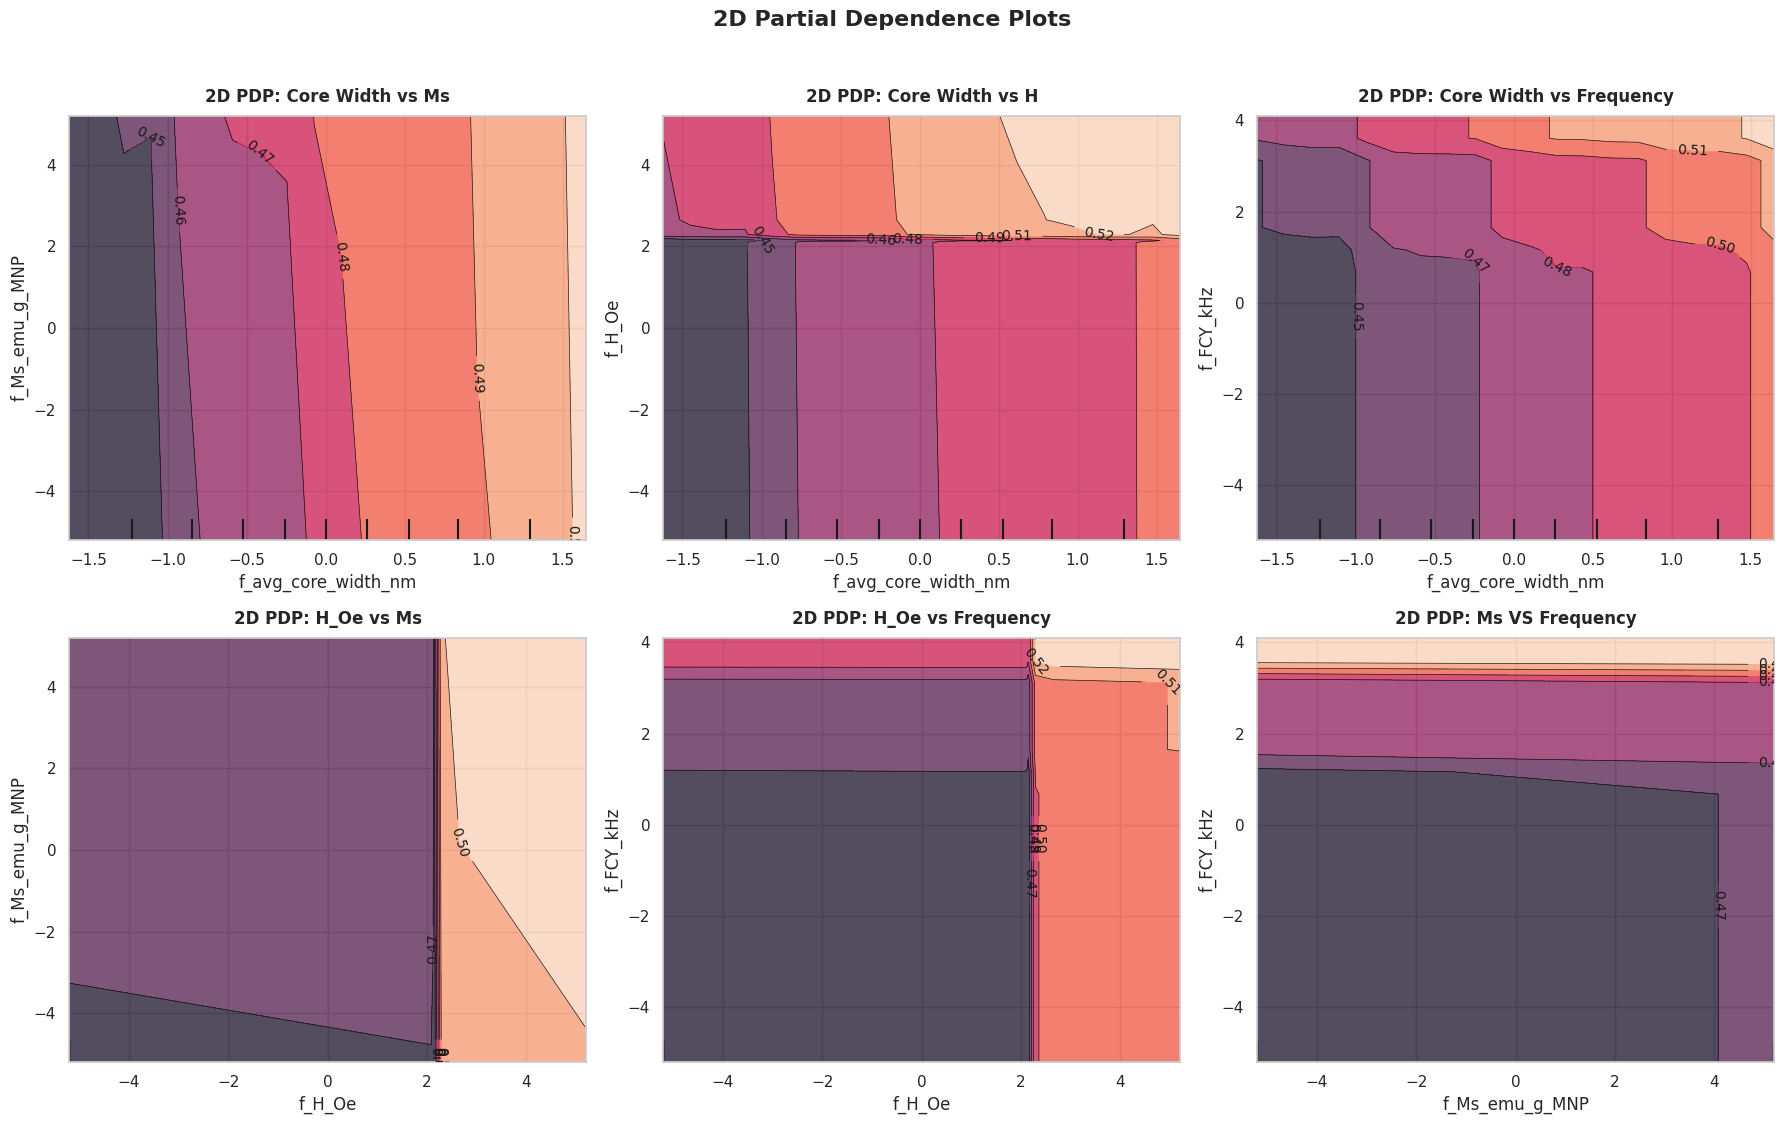

In [ ]:
pairs = [
    ('f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'Core Width vs Ms'),
    ('f_avg_core_width_nm', 'f_H_Oe',          'Core Width vs H'),
    ('f_avg_core_width_nm', 'f_FCY_kHz',       'Core Width vs Frequency'),
    ('f_H_Oe',              'f_Ms_emu_g_MNP', 'H_Oe vs Ms'),
    ('f_H_Oe',              'f_FCY_kHz',       'H_Oe vs Frequency'),
    ('f_Ms_emu_g_MNP',  'f_FCY_kHz' , 'Ms VS Frequency')
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes_flat = axes.flatten()

for idx, (feat_a, feat_b, title) in enumerate(pairs):
    ax = axes_flat[idx]

    try:
        PartialDependenceDisplay.from_estimator(
            catboost_model,
            X_train,
            features=[(feat_a, feat_b)],
            kind='average',
            ax=ax,
            grid_resolution=20
        )
        ax.set_title(f'2D PDP: {title}', fontsize=12, fontweight='bold', pad=10)

    except ValueError as e:
        print(f"Skipping plot for ({feat_a}, {feat_b}) due to error: {e}")
        ax.set_visible(False)

if len(pairs) < len(axes_flat):
    for unused_ax in axes_flat[len(pairs):]:
        fig.delaxes(unused_ax)

plt.suptitle('2D Partial Dependence Plots', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

plt.savefig('pdp_2d_all_pairs_subplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
OPT_VARS = [
    "f_avg_core_width_nm",
    "f_Ms_emu_g_MNP",
    "f_Hc_Oe",
    "f_H_Oe",
    "f_FCY_kHz",
    "Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp",   # Fe_comp removed -- now derived
]

BOUNDS = [
    (5.0, 30.0),      # f_avg_core_width_nm
    (60.0, 150.0),    # f_Ms_emu_g_MNP
    (0.0, 100.0),     # f_Hc_Oe
    (5.0, 300.0),     # f_H_Oe
    (100.0, 500.0),   # f_FCY_kHz
    (0.05, 0.20),        # Zn_comp
    (0.05, 0.20),        # Co_comp
    (0.05, 0.20),        # Ca_comp
    (0.05, 0.20),        # Cu_comp
    (0.05, 0.20)        # Ni_comp
    # Fe_comp is no longer a free DE dimension
]

DIRECTION_WEIGHTS = {
    "f_avg_core_width_nm": -1.0,   # minimize core width
    "f_Hc_Oe":             -1.0,   # minimize coercivity
    "f_FCY_kHz":           -1.0,   # minimize applied frequency
    "f_Ms_emu_g_MNP":      +1.0,   # maximize saturation magnetization
    "f_H_Oe":               +1.0,  # maximize applied field
}

TARGET_WEIGHT   = 15.0
SAR_SCALE       = 2000.0
DOPANT_COLS     = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp", "Fe_comp"]
MAX_DOPANT_SUM  = 3.0
LRT_HF_LIMIT    = 5.0e9
OE_TO_A_M       = 79.577
CONSTRAINT_PENALTY = 50.0

N_CANDIDATES     = 20
DIVERSITY_RADIUS = 0.5
DIVERSITY_LAMBDA = 1.0
POPSIZE          = 20
MAXITER          = 150

OPT_IDX  = {name: i for i, name in enumerate(OPT_VARS)}
H_IDX    = OPT_IDX["f_H_Oe"]
F_IDX    = OPT_IDX["f_FCY_kHz"]
DOPANT_IDXS = [OPT_IDX[c] for c in DOPANT_COLS if c in OPT_IDX]
FREE_DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp"]
FE_COL           = "Fe_comp"
FE_BOUNDS        = (1.0, 3.0)
DOPANT_SUM_TARGET = 3.0
FREE_DOPANT_IDXS = [OPT_IDX[c] for c in FREE_DOPANT_COLS]



BOUNDS_ARR = np.array(BOUNDS)
BOUNDS_LO  = BOUNDS_ARR[:, 0]
BOUNDS_HI  = BOUNDS_ARR[:, 1]

def normalize(X):
    return (X - BOUNDS_LO) / (BOUNDS_HI - BOUNDS_LO + 1e-8)

def compute_fe_comp(X: np.ndarray) -> np.ndarray:
    return DOPANT_SUM_TARGET - X[:, FREE_DOPANT_IDXS].sum(axis=1)

def make_baseline_row(X_raw: pd.DataFrame, mode: str = "median") -> pd.DataFrame:
    row = X_raw.iloc[[0]].copy()
    for col in X_raw.columns:
        if pd.api.types.is_numeric_dtype(X_raw[col]):
            row[col] = X_raw[col].median() if mode == "median" else X_raw[col].iloc[0]
        else:
            row[col] = X_raw[col].mode().iloc[0] if mode == "median" else X_raw[col].iloc[0]
    return row

def batch_predict_sar(X: np.ndarray, model, transf, y_scaler,
                       baseline_row_raw: pd.DataFrame, feature_names,
                       numeric_cols, opt_vars=OPT_VARS) -> np.ndarray:
    n = X.shape[0]
    batch = pd.concat([baseline_row_raw] * n, ignore_index=True)
    for j, name in enumerate(opt_vars):
        batch[name] = X[:, j]

    batch[FE_COL] = compute_fe_comp(X)

    batch[numeric_cols] = transf.transform(batch[numeric_cols])

    y_model = model.predict(batch[feature_names])
    y_log   = y_scaler.inverse_transform(y_model.reshape(-1, 1)).flatten()
    return np.expm1(y_log)


def objective_vectorized(X_T, model, transf, y_scaler, baseline_row_raw,
                          feature_names, numeric_cols, penalized_points,
                          debug=False):
    X = X_T.T
    n = X.shape[0]
    X_norm = normalize(X)

    sar = batch_predict_sar(X, model, transf, y_scaler, baseline_row_raw,
                             feature_names, numeric_cols)

    raw_structural_score = np.zeros(n)
    for name, weight in DIRECTION_WEIGHTS.items():
        i = OPT_IDX[name]
        raw_structural_score += -weight * X_norm[:, i]
    raw_structural_score /= len(DIRECTION_WEIGHTS)

    raw_sar_score = -TARGET_WEIGHT * (sar / SAR_SCALE)

    h_am = X[:, H_IDX] * OE_TO_A_M
    f_hz = X[:, F_IDX] * 1000.0
    hf_violation = np.maximum(0.0, (h_am * f_hz) - LRT_HF_LIMIT) / LRT_HF_LIMIT

    fe_comp = compute_fe_comp(X)
    fe_lo, fe_hi = FE_BOUNDS
    fe_violation = (np.maximum(0.0, fe_lo - fe_comp) +
                     np.maximum(0.0, fe_comp - fe_hi)) / (fe_hi - fe_lo)

    penalty = CONSTRAINT_PENALTY * (hf_violation + fe_violation)

    score = raw_structural_score + raw_sar_score + penalty

    diversity_term = np.zeros(n)
    if penalized_points:
        P = np.array(penalized_points)
        P_norm = normalize(P)
        dists = cdist(X_norm, P_norm)
        proximity = np.exp(-(dists ** 2) / (2 * DIVERSITY_RADIUS ** 2)).sum(axis=1)
        diversity_term = DIVERSITY_LAMBDA * proximity
        score = score + diversity_term

    if debug:
        print(f"  structural: mean={raw_structural_score.mean():+.3f} | "
              f"sar: mean={raw_sar_score.mean():+.3f} | "
              f"hf_pen: mean={hf_violation.mean():+.3f} | "
              f"fe_pen: mean={fe_violation.mean():+.3f} | "
              f"diversity: mean={diversity_term.mean():+.3f}")

    return score

from itertools import combinations
import random

FREE_DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp"]
FE_COL           = "Fe_comp"
FE_BOUNDS        = (1.0, 3.0)
DOPANT_SUM_TARGET = 3.0

FREE_DOPANT_IDXS = [OPT_IDX[c] for c in FREE_DOPANT_COLS]

def make_bounds_for_mask(active_names, base_bounds=BOUNDS):
    bounds = list(base_bounds)
    for name in FREE_DOPANT_COLS:
        i = OPT_IDX[name]
        if name in active_names:
            bounds[i] = base_bounds[i]
        else:
            bounds[i] = (0.0, 0.0)
    return bounds

def optimize_for_subset(active_names, model, transf, y_scaler, feature_names, numeric_cols,
                         baseline_row_raw, n_candidates=N_CANDIDATES, seed_offset=0):
    bounds = make_bounds_for_mask(active_names)
    penalized_points = []
    rows = []

    for i in range(n_candidates):
        result = differential_evolution(
            objective_vectorized,
            bounds=bounds,
            args=(model, transf, y_scaler, baseline_row_raw, feature_names,
                  numeric_cols, penalized_points),
            vectorized=True,
            updating="deferred",
            popsize=POPSIZE,
            maxiter=MAXITER,
            tol=1e-7,
            mutation=(0.4, 1.0),
            recombination=0.7,
            polish=False,
            seed=RANDOM_STATE + seed_offset + i,
        )
        best_x = result.x
        penalized_points.append(best_x)

        pred_sar = batch_predict_sar(
            best_x.reshape(1, -1), model, transf, y_scaler,
            baseline_row_raw, feature_names, numeric_cols
        )[0]

        fe_comp = float(compute_fe_comp(best_x.reshape(1, -1))[0])
        dopant_sum = float(best_x[FREE_DOPANT_IDXS].sum() + fe_comp)
        hf_product = float(best_x[H_IDX] * OE_TO_A_M * best_x[F_IDX] * 1000.0)
        fe_ok = FE_BOUNDS[0] <= fe_comp <= FE_BOUNDS[1]

        row = dict(zip(OPT_VARS, best_x))
        row["Fe_comp"] = fe_comp
        row["Predicted_SAR_W_g"] = pred_sar
        row["Dopant_Sum"] = dopant_sum
        row["Hf_product"] = hf_product
        row["Active_Dopants"] = "+".join(active_names)
        row["Constraint_Satisfied"] = bool(hf_product <= LRT_HF_LIMIT and fe_ok)
        rows.append(row)

        print(f"Candidate {i+1:2d}/{n_candidates} [{'+'.join(active_names)}] | "
              f"Predicted SAR = {pred_sar:8.2f} W/g | "
              f"Dopant Sum = {dopant_sum:.4f} | Fe_comp = {fe_comp:.3f} "
              f"(bounds {FE_BOUNDS}) | "
              f"H*f = {hf_product:.3e} (limit {LRT_HF_LIMIT:.1e}) | "
              f"OK={row['Constraint_Satisfied']}")

    out = pd.DataFrame(rows).sort_values("Predicted_SAR_W_g", ascending=False).reset_index(drop=True)
    return out


def optimize_across_dopant_subsets(model, transf, y_scaler, feature_names, numeric_cols,
                                    baseline_row_raw, subset_sizes=(2, 3, 5),
                                    max_subsets_per_size=8, n_candidates_per_subset=3):
    all_results = []
    seed_offset = 0
    random.seed(RANDOM_STATE)

    for size in subset_sizes:
        subsets = list(combinations(FREE_DOPANT_COLS, size))
        if len(subsets) > max_subsets_per_size:
            subsets = random.sample(subsets, max_subsets_per_size)

        for active_names in subsets:
            print(f"\n--- Optimizing subset: {'+'.join(active_names)} "
                  f"({size} active dopant(s) + Fe) ---")
            df = optimize_for_subset(list(active_names), model, transf, y_scaler,
                                      feature_names, numeric_cols, baseline_row_raw,
                                      n_candidates_per_subset, seed_offset)
            all_results.append(df)
            seed_offset += n_candidates_per_subset

    out = pd.concat(all_results, ignore_index=True)
    out = out.sort_values("Predicted_SAR_W_g", ascending=False).reset_index(drop=True)
    return out

In [ ]:
baseline_row = make_baseline_row(x_train, mode="median")
feature_names = x_train.columns.tolist()

top20 = optimize_across_dopant_subsets(
    model=model,
    transf=transf,
    y_scaler=y_scaler,
    feature_names=feature_names,
    numeric_cols=numeric_cols,
    baseline_row_raw=baseline_row,
    subset_sizes=(2,3,4,5),
    max_subsets_per_size=10,
    n_candidates_per_subset=3,
)


--- Optimizing subset: Zn_comp+Co_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Ca_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Cu_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Ni_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Co_comp+Ca_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Co_comp+Cu_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Co_comp+Ni_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Ca_comp+Cu_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Ca_comp+Ni_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Cu_comp+Ni_comp (2 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Co_comp+Ca_comp (3 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Co_comp+Cu_comp (3 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Co_comp+Ni_comp (3 active dopant(s) + Fe) ---

--- Optimizing subset: Zn_comp+Ca_comp+Cu_comp (3 active dopant(s

KeyboardInterrupt: 

In [ ]:
DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp", "Fe_comp"]

def format_composition(row):
    parts = []
    for dopant in FREE_DOPANT_COLS:
        val = row[dopant]
        if val > 0:
            symbol = dopant.replace("_comp", "")
            parts.append(f"{symbol}{val:.2f}")
    parts.append(f"Fe{row['Fe_comp']:.2f}")
    return "".join(parts) + "O4"

top20["Composition"] = top20.apply(format_composition, axis=1)

cols_to_show = (OPT_VARS + ["Fe_comp", "Composition", "Predicted_SAR_W_g",
                             "Dopant_Sum", "Hf_product", "Constraint_Satisfied"])
print(top20[cols_to_show].round(3).to_string())

n_ok = int(top20["Constraint_Satisfied"].sum())
print(f"\n{n_ok}/{len(top20)} candidates satisfy the LRT safety limit and dopant-sum constraint.")

top20.to_excel("top_candidates_tabpfn.xlsx", index=False)